In [1]:
!pip install qiskit qiskit-aer matplotlib numpy pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 20.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 39.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 53.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit-aer]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

<>:29: SyntaxWarning: invalid escape sequence '\D'
<>:29: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2603/3863839804.py:29: SyntaxWarning: invalid escape sequence '\D'
  plt.title('Oscilaciones de Rabi en la molécula de $NH_3$ (Detuning $\Delta = \Omega/2$)', fontsize=13)


Frecuencia base (f_0): 2.4790e+10 Hz
Frecuencia de Rabi generalizada (f_R): 2.7716e+10 Hz (27.72 GHz)


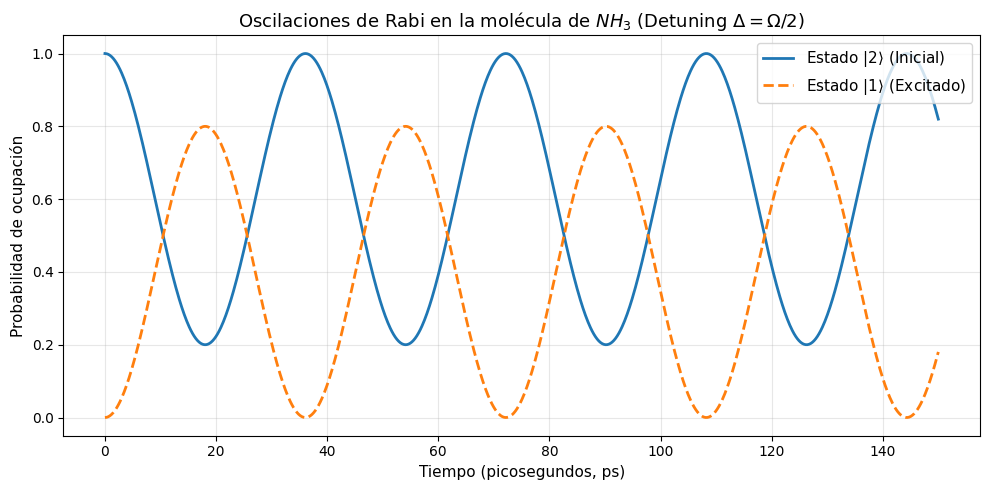

In [3]:
f_0 = 24.79e9  # Frecuencia en Hz (24.79 GHz)
Omega = 2 * np.pi * f_0  # Frecuencia angular de Rabi sin detuning (rad/s)

Delta = Omega / 2.0

Omega_R_rad = np.sqrt(Omega**2 + Delta**2)
f_R_Hz = Omega_R_rad / (2 * np.pi)

print(f"Frecuencia base (f_0): {f_0:.4e} Hz")
print(f"Frecuencia de Rabi generalizada (f_R): {f_R_Hz:.4e} Hz ({f_R_Hz/1e9:.2f} GHz)")

t = np.linspace(0, 150e-12, 1000)  # Tiempo de 0 a 150 ps


P_1 = (Omega**2 / Omega_R_rad**2) * (np.sin(Omega_R_rad * t / 2)**2)
P_2 = 1 - P_1

plt.figure(figsize=(10, 5))
plt.plot(t * 1e12, P_2, label=r'Estado $|2\rangle$ (Inicial)', linewidth=2)
plt.plot(t * 1e12, P_1, label=r'Estado $|1\rangle$ (Excitado)', linestyle='--', linewidth=2)

plt.title('Oscilaciones de Rabi en la molécula de $NH_3$ (Detuning $\Delta = \Omega/2$)', fontsize=13)
plt.xlabel('Tiempo (picosegundos, ps)', fontsize=11)
plt.ylabel('Probabilidad de ocupación', fontsize=11)
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right', fontsize=11)
plt.tight_layout()
plt.show()

#Exercise Bell State


In [ ]:
Para graficar los qubits usareemos qc.draw que se explicó en el notebook de la clase cómo la forma más fácil de visualizar el circuito

1) Creates a quantum circuit for two qubits, consisting of the quantum gates needed to create a Bell state (two entangled qubits). The quantum circuit then terminates with quantum measurements, extracting one bit from each qubit.

--- 1. Circuito Estado de Bell (2 Qubits) ---


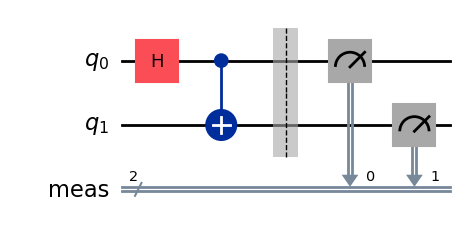

Resultados Bell State: {'11': 515, '00': 509} 



In [17]:
qc_bell = QuantumCircuit(2)
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure_all()

print("--- 1. Circuito Estado de Bell (2 Qubits) ---")
display(qc_bell.draw('mpl'))  # Dibuja el circuito gráficamente

counts_1 = simulator.run(qc_bell, shots=1024).result().get_counts()
print("Resultados Bell State:", counts_1, "\n")

2) Add a third qubit by changing to QuantumCircuit(3), and add a second CX gate with qc.cx(1,2). The measurements should then change to 000 and 111, which means all three of these qubits have been entangled.

--- 2. Circuito 3 Qubits Entrelazados (GHZ) ---


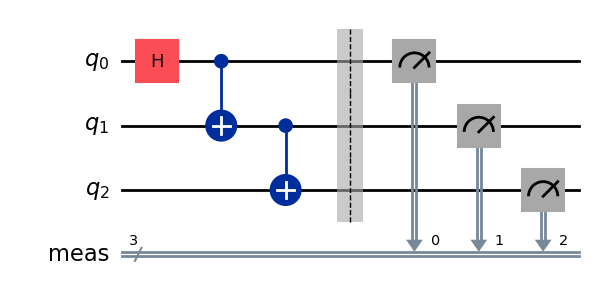

Resultados 3 Qubits: {'000': 500, '111': 524} 



In [18]:
qc_ghz = QuantumCircuit(3)
qc_ghz.h(0)
qc_ghz.cx(0, 1)
qc_ghz.cx(1, 2)
qc_ghz.measure_all()

print("--- 2. Circuito 3 Qubits Entrelazados (GHZ) ---")
display(qc_ghz.draw('mpl'))   # Dibuja el circuito gráficamente

counts_2 = simulator.run(qc_ghz, shots=1024).result().get_counts()
print("Resultados 3 Qubits:", counts_2, "\n")

3) See your results shift by adding qc.x(1) to the end of the circuit.

--- 3. Circuito con qc.x(1) al final ---


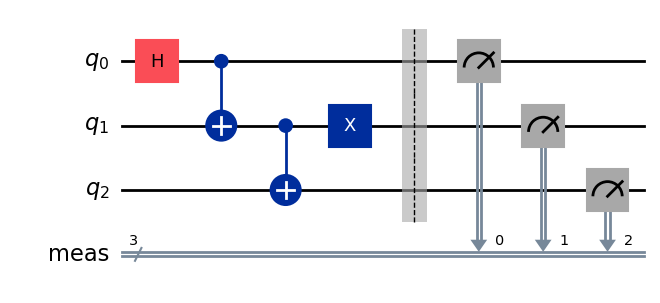

Resultados con Shift qc.x(1): {'101': 508, '010': 516}


In [25]:
qc_shift = QuantumCircuit(3)
qc_shift.h(0)
qc_shift.cx(0, 1)
qc_shift.cx(1, 2)
qc_shift.x(1)
qc_shift.measure_all()

print("--- 3. Circuito con qc.x(1) al final ---")
display(qc_shift.draw('mpl')) # Dibuja el circuito gráficamente

counts_3 = simulator.run(qc_shift, shots=1024).result().get_counts()
print("Resultados con Shift qc.x(1):", counts_3)

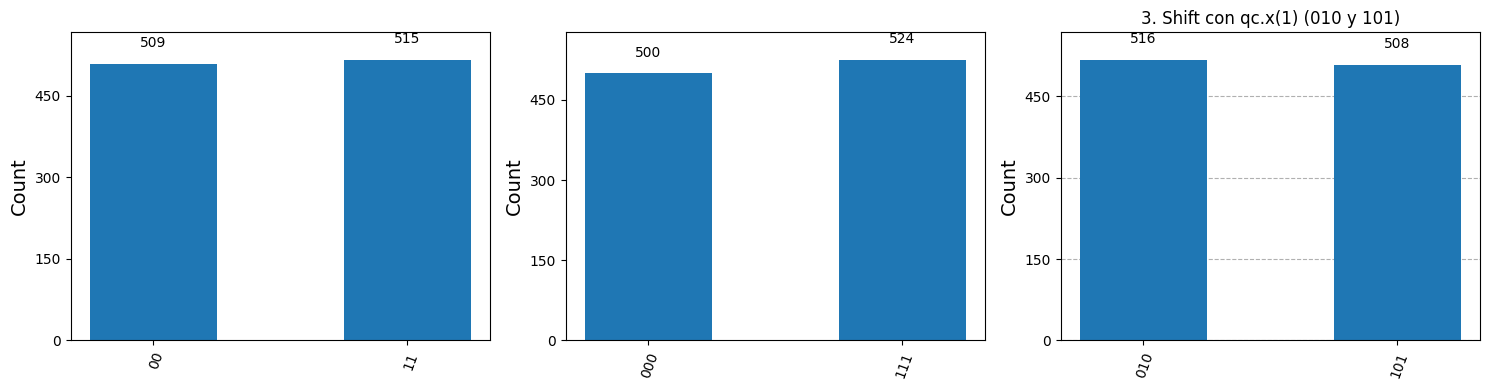

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_histogram(counts_1, ax=axes[0], title="1. Bell State (2 Qubits)")
plot_histogram(counts_2, ax=axes[1], title="2. 3 Qubits (000 y 111)")
plot_histogram(counts_3, ax=axes[2], title="3. Shift con qc.x(1) (010 y 101)")

plt.tight_layout()
plt.show()